# Advisory analysis
Inputs (all local, nothing is crawled): `../Step:1_Crawler/Step2_structure_dataset/structureddataset.xlsx` and `../Step:1_Crawler/Step3_CVE_collection/cvedata/` (one NVD JSON per CVE).
Outputs: `Equipmentseparateddata.xlsx` (615 rows), top CWEs, most vulnerable equipment, attack vector by severity heatmap.

## Part A: Build the equipment and vulnerability dataset

In [20]:
import os, re, json
import pandas as pd

data = pd.read_excel('../Step_1_Crawler/Step2_structure_dataset/structureddataset.xlsx')
data = data.dropna()
print('advisories after vendor-name fix:', data.shape[0])

advisories after vendor-name fix: 128


In [21]:
# Split the Equipment column into one row per device
def split_equipment(equipment):
    parts = re.split(r',|;|\band\b|&', equipment)
    return [p.strip() for p in parts if p.strip()]

data['Equipment'] = data['Equipment'].apply(split_equipment)
exploded_data = data.explode('Equipment').reset_index(drop=True)
print('rows after equipment split:', exploded_data.shape[0])

rows after equipment split: 202


In [22]:
# Split the CVE_IDs column into one row per CVE
def split_cve(cve):
    return [c.strip() for c in re.split(r',', cve) if c.strip()]

exploded_data['CVE_IDs'] = exploded_data['CVE_IDs'].apply(split_cve)
exploded_data = exploded_data.explode('CVE_IDs').reset_index(drop=True)
print('rows after CVE split:', exploded_data.shape[0])

rows after CVE split: 687


In [23]:
Insightdf = exploded_data[['Vendor', 'Equipment', 'CVE_IDs', 'CVSS']].copy()
Insightdf['CVE_IDs'] = Insightdf['CVE_IDs'].str.upper()

In [24]:
# Read attack-vector / CWE / CPE fields from the local NVD JSON files
def extract_info(entry):
    info = {}
    cve = entry['cve']
    if 'metrics' in cve:
        metrics = cve['metrics']
        if 'cvssMetricV31' in metrics:
            cvss = metrics['cvssMetricV31'][0]['cvssData']
        elif 'cvssMetricV30' in metrics:
            cvss = metrics['cvssMetricV30'][0]['cvssData']
        elif 'cvssMetricV40' in metrics:
            cvss = metrics['cvssMetricV40'][0]['cvssData']
        else:
            cvss = {}
        for field in ['attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction',
                      'scope', 'confidentialityImpact', 'integrityImpact', 'availabilityImpact']:
            info[field] = cvss.get(field, '')
    if 'weaknesses' in cve and cve['weaknesses']:
        weaknesses = cve['weaknesses']
        primary = next((w for w in weaknesses if w['type'] == 'Primary'), None)
        info['CWE'] = (primary or weaknesses[0])['description'][0]['value']
    if 'configurations' in cve:
        configs = cve['configurations']
        if configs and 'nodes' in configs[0]:
            nodes = configs[0]['nodes']
            if nodes and 'cpeMatch' in nodes[0]:
                info['cpe'] = nodes[0]['cpeMatch'][0].get('criteria', '')
    return info

cve_dir = '../Step_1_Crawler/Step3_CVE_collection/cvedata'
cve_info = {}
for filename in os.listdir(cve_dir):
    if filename.endswith('.json'):
        cve_id = filename.split('.')[0].lower()
        with open(os.path.join(cve_dir, filename), 'r') as f:
            js = json.load(f)
        if 'vulnerabilities' in js and js['vulnerabilities']:
            cve_info[cve_id] = extract_info(js['vulnerabilities'][0])
print('CVE JSON files loaded:', len(cve_info))

CVE JSON files loaded: 350


In [25]:
new_columns = ['attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction', 'scope',
               'confidentialityImpact', 'integrityImpact', 'availabilityImpact', 'CWE', 'cpe']
for col in new_columns:
    Insightdf[col] = ''
for index, row in Insightdf.iterrows():
    cve_id = row['CVE_IDs'].lower()
    if cve_id in cve_info:
        for col in new_columns:
            Insightdf.at[index, col] = cve_info[cve_id].get(col, '')

# Keep only the CWE-<number> part of the CWE field
def clean_cwe(value):
    if pd.isna(value):
        return None
    match = re.search(r'CWE-\d+', str(value))
    return match.group() if match else None
Insightdf['CWE'] = Insightdf['CWE'].apply(clean_cwe)

In [26]:
# Drop rows with any empty value
empty_tokens = ['', 'nan', 'None', 'NaN', 'null', 'NULL']
empty_mask = Insightdf.isnull() | Insightdf.astype(str).isin(empty_tokens)
rows_with_empty = empty_mask.any(axis=1)
print('rows dropped:', rows_with_empty.sum())
Insightdf = Insightdf[~rows_with_empty].reset_index(drop=True)
print('final equipment-vulnerability pairs:', Insightdf.shape[0])
Insightdf.to_excel('Equipmentseparateddata.xlsx')

rows dropped: 72
final equipment-vulnerability pairs: 615


## Part B: Results
Reads `Equipmentseparateddata.xlsx` written by Part A.

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_excel('Equipmentseparateddata.xlsx')
data = data.drop(data.columns[0], axis=1)
print('rows:', data.shape[0])

rows: 615


In [29]:
print('unique CVEs:', data['CVE_IDs'].nunique())
print('unique CWEs:', data['CWE'].nunique())
print('unique equipment:', data['Equipment'].nunique())

unique CVEs: 297
unique CWEs: 84
unique equipment: 171


In [30]:
# Top CWEs
cwe_counts = data['CWE'].value_counts().head(9)
print(cwe_counts)

CWE
CWE-287    59
CWE-798    46
CWE-330    41
CWE-20     34
CWE-522    31
CWE-120    29
CWE-79     27
CWE-319    26
CWE-306    21
Name: count, dtype: int64


In [31]:
# Most vulnerable equipment (ties at the cut-off are all listed)
equip_counts = data['Equipment'].value_counts()
cutoff = equip_counts.iloc[4]
top_equipment = equip_counts[equip_counts >= cutoff].index
top_equipment_table = (data[data['Equipment'].isin(top_equipment)]
          .groupby(['Equipment', 'Vendor']).size().reset_index(name='Vulnerability Count')
          .sort_values(['Vulnerability Count', 'Equipment'], ascending=[False, True]))
print(top_equipment_table.to_string(index=False))

                             Equipment                Vendor  Vulnerability Count
                              Vue PACS               Philips                   19
        Agilia Connect Infusion System        Fresenius Kabi                   13
            Battery Pack SP with Wi-Fi B. Braun Melsungen AG                   11
                         OpenClinic GA          Source Forge                   11
               Data module compactplus B. Braun Melsungen AG                   10
INTEGRITY RTOS by Green Hills Software  Green Hills Software                   10
                                 ITRON                 ITRON                   10
                           OSE by ENEA                  ENEA                   10
                              SpaceCom B. Braun Melsungen AG                   10
                 VxWorks by Wind River            Wind River                   10
                  ZebOS by IP Infusion           IP Infusion                   10


CVSS              Critical  High  Medium  Low
attackVector                                 
ADJACENT_NETWORK        19    67     113    1
LOCAL                    7    26      13    5
NETWORK                155    85      39    2
PHYSICAL                 0    29      52    2


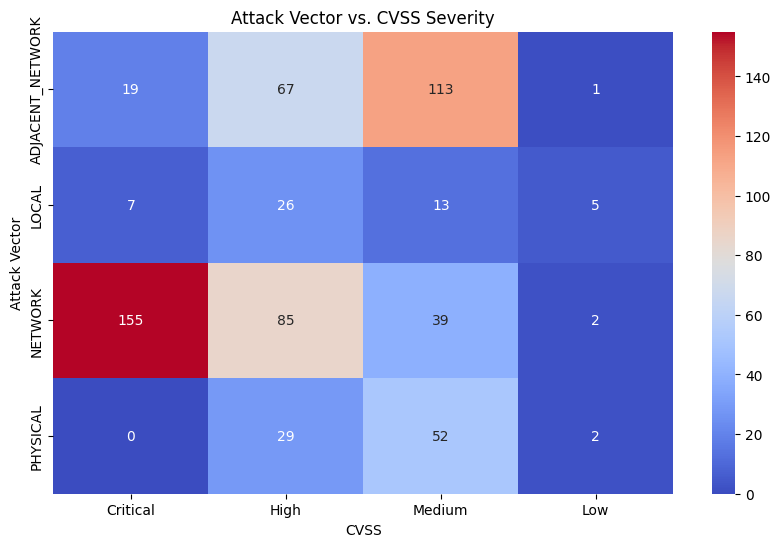

In [32]:
# Attack vector by CVSS severity
attack_vector_cvss = pd.crosstab(data['attackVector'], data['CVSS'])[['Critical', 'High', 'Medium', 'Low']]
print(attack_vector_cvss)
plt.figure(figsize=(10, 6))
sns.heatmap(attack_vector_cvss, annot=True, cmap='coolwarm', fmt='d')
plt.title('Attack Vector vs. CVSS Severity')
plt.xlabel('CVSS')
plt.ylabel('Attack Vector')
plt.savefig('fig2_attackvector_cvss.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
# Share of Critical and High vulnerabilities that have a NETWORK attack vector
crit_high = data[data['CVSS'].isin(['Critical', 'High'])]
n_network = (crit_high['attackVector'] == 'NETWORK').sum()
print(n_network, '/', len(crit_high), '=', round(100 * n_network / len(crit_high), 1), '%')

240 / 388 = 61.9 %
